# Deep Learning Model (TensorFlow/Keras)

## 11.1 Imports

In [8]:
# Standard Libraries

import os
import gc
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


# Data Manipulation

import numpy as np
import pandas as pd


# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Machine Learning Models

import tensorflow as tf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# Evaluation


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# TensorFlow

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers

In [9]:
# Project Configuration

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

FIGSIZE = (12,6)

print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

TensorFlow Version : 2.21.0
NumPy Version      : 2.5.1
Pandas Version     : 3.0.5


---

## 11.2 Reproducibility

In [10]:

# Reproducibility


tf.keras.utils.set_random_seed(RANDOM_STATE)

tf.config.experimental.enable_op_determinism()

# Load data from disk

In [15]:
DATA_DIR = Path("data/Training_Datasets")
RESULT_DIR = Path('Results')

# -----------------------------
# Features
# -----------------------------
X_train_scaled = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_valid_scaled = pd.read_csv(DATA_DIR / "X_valid_scaled.csv")
X_test_scaled  = pd.read_csv(DATA_DIR / "X_test_scaled.csv")

X_train_tree = pd.read_csv(DATA_DIR / "X_train_tree.csv")
X_valid_tree = pd.read_csv(DATA_DIR / "X_valid_tree.csv")
X_test_tree  = pd.read_csv(DATA_DIR / "X_test_tree.csv")

# -----------------------------
# Targets
# -----------------------------
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_valid = pd.read_csv(DATA_DIR / "y_valid.csv").squeeze("columns")
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

# -----------------------------
# Restults
# -----------------------------

ML_results = pd.read_csv(RESULT_DIR/"ML_models_results.csv")

print("Datasets loaded successfully.")

Datasets loaded successfully.


### Compute Class Weights

Instead of immediately applying SMOTE, we'll first use class weights.

In [25]:
from sklearn.utils.class_weight import compute_class_weight

In [26]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

In [27]:
class_weights = dict(
    zip(classes, weights)
)

print(class_weights)

{np.int64(0): np.float64(0.5182253535252231), np.int64(1): np.float64(14.217155041959003)}


Using class weights is a strong baseline for highly imbalanced fraud detection because it increases the cost of misclassifying minority-class examples without generating synthetic transactions. Many recent IEEE-CIS studies evaluate class weighting before introducing oversampling methods such as SMOTE.

---

## 11.3 Input Dimension

In [16]:
INPUT_DIM = X_train_scaled.shape[1]

print(INPUT_DIM)

436


---

# 11.4 Build Neural Network

Instead of Sequential API, we'll use the Functional API.

In [17]:

# Neural Network


def build_model(input_dim):

    inputs = keras.Input(shape=(input_dim,))

    x = layers.Dense(
        512,
        kernel_regularizer=regularizers.l2(1e-4)
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)

    x = layers.Dropout(0.40)(x)

    x = layers.Dense(
        256,
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)

    x = layers.Dropout(0.30)(x)

    x = layers.Dense(
        128,
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)

    x = layers.Activation("relu")(x)

    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    return model

---

## 11.5 Create Model

In [18]:
model = build_model(INPUT_DIM)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 436)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         223,744 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 391,681 (1.49 MB)

 Trainable params: 389,889 (1.49 MB)

 Non-trainable params: 1,792 (7.00 KB)

---

# 11.6 Compile Model

Instead of tracking only accuracy, we'll monitor metrics that matter for fraud detection.

In [19]:
METRICS = [

    keras.metrics.BinaryAccuracy(
        name="accuracy"
    ),

    keras.metrics.Precision(
        name="precision"
    ),

    keras.metrics.Recall(
        name="recall"
    ),

    keras.metrics.AUC(
        name="roc_auc"
    ),

    keras.metrics.AUC(
        curve="PR",
        name="pr_auc"
    )

]

TensorFlow's `AUC(curve="PR")` is specifically designed for Precision-Recall AUC, which is often more informative than accuracy for highly imbalanced binary classification tasks.

In [20]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="binary_crossentropy",

    metrics=METRICS

)

Binary cross-entropy is the standard loss for binary classification with sigmoid outputs.

# 11.7 Callbacks

In [21]:
early_stop = keras.callbacks.EarlyStopping(

    monitor="val_pr_auc",

    mode="max",

    patience=10,

    restore_best_weights=True

)

In [22]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    verbose=1

)

In [23]:
checkpoint = keras.callbacks.ModelCheckpoint(

    "models/best_nn.keras",

    monitor="val_pr_auc",

    mode="max",

    save_best_only=True,

    verbose=1

)

Monitoring validation PR-AUC with EarlyStopping is a sensible choice for fraud detection because it aligns training with the evaluation objective on imbalanced data.

# 11.8 Train

In [28]:
history = model.fit(

    X_train_scaled,

    y_train,

    validation_data=(

        X_valid_scaled,

        y_valid

    ),

    epochs=100,

    batch_size=1024,

    class_weight=class_weights,

    callbacks=[

        early_stop,

        reduce_lr,

        checkpoint

    ],

    verbose=1

)

Epoch 1/100
404/404 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7887 - loss: 0.5827 - pr_auc: 0.3381 - precision: 0.1154 - recall: 0.7511 - roc_auc: 0.8498
Epoch 1: val_pr_auc improved from None to 0.39062, saving model to models/best_nn.keras

Epoch 1: finished saving model to models/best_nn.keras
404/404 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7887 - loss: 0.5827 - pr_auc: 0.3381 - precision: 0.1154 - recall: 0.7511 - roc_auc: 0.8498 - val_accuracy: 0.7255 - val_loss: nan - val_pr_auc: 0.3906 - val_precision: 0.0931 - val_recall: 0.8005 - val_roc_auc: 0.8433 - learning_rate: 0.0010
Epoch 2/100
401/404 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8229 - loss: 0.5209 - pr_auc: 0.4421 - precision: 0.1389 - recall: 0.7758 - roc_auc: 0.8794
Epoch 2: val_pr_auc improved from 0.39062 to 0.41609, saving model to models/best_nn.keras

Epoch 2: finished saving model to models/best_nn.keras
404/404 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8227 - loss: 0.5205 - pr_auc: 0.44

Using `class_weight` is a common approach for fraud detection because it increases the contribution of minority-class errors during optimization without generating synthetic samples.

---

# 11.9 Plot Training History

In [29]:
history_df = pd.DataFrame(history.history)

display(history_df.head())

,accuracy,loss,pr_auc,precision,recall,roc_auc,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,learning_rate
0,0.788707,0.582715,0.338111,0.115369,0.751066,0.849843,0.725517,NaN,0.390624,0.093145,0.800460,0.843290,0.001
1,0.822719,0.520516,0.442421,0.138753,0.776035,0.879578,0.759881,NaN,0.416089,0.104049,0.787311,0.852377,0.001
2,0.835151,0.490212,0.476210,0.149879,0.789242,0.891946,0.787584,NaN,0.420785,0.115118,0.775477,0.855711,0.001
3,0.838530,0.470370,0.495419,0.153890,0.798390,0.899186,0.764927,NaN,0.418550,0.107293,0.798488,0.857910,0.001
4,0.844556,0.453364,0.513419,0.160162,0.805888,0.905131,0.795069,NaN,0.426152,0.119466,0.779750,0.860237,0.001


---

## Loss

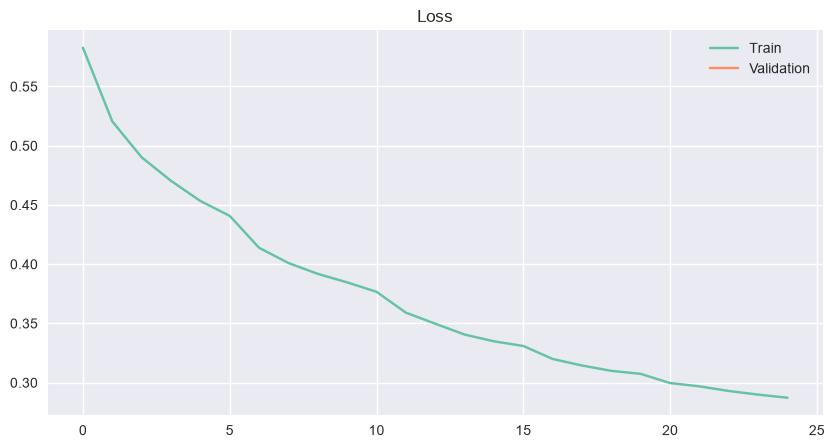

In [30]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history["loss"],
    label="Train"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.legend()

plt.title("Loss")

plt.show()

## PR-AUC

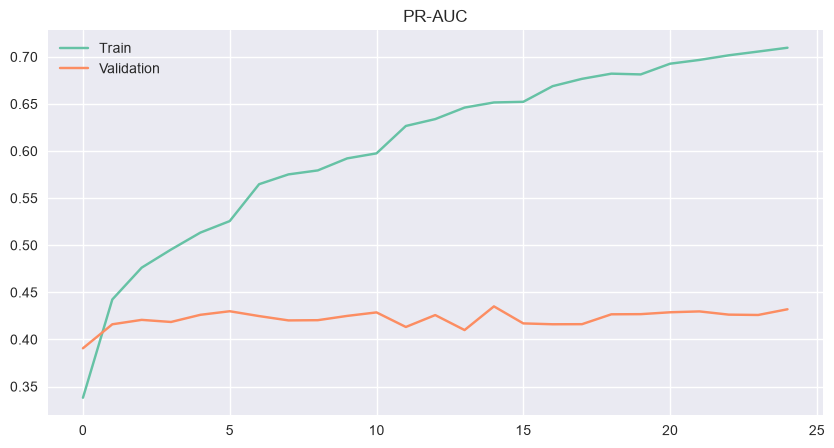

In [31]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history["pr_auc"],
    label="Train"
)

plt.plot(
    history.history["val_pr_auc"],
    label="Validation"
)

plt.legend()

plt.title("PR-AUC")

plt.show()

**Note:**
At this point, **the neural network has only been trained**.

We have **not evaluated it in the same way as the machine learning models**. To make a fair comparison, we still need to:

1. Generate prediction probabilities on the validation set.
2. Optimize the classification threshold (instead of using 0.5).
3. Compute the same metrics (ROC-AUC, PR-AUC, Precision, Recall, F1).
4. Plot the confusion matrix, ROC curve, and Precision-Recall curve.
5. Add the neural network results to our `results_df` alongside Random Forest, XGBoost, LightGBM, and CatBoost.

# Neural Network Evaluation & Final Model Comparison

Unlike the classical ML models, we haven't yet evaluated the neural network using the same pipeline.

Let's fix that.

# 12.1 Predict Probabilities

In [99]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_scaled = imputer.fit_transform(X_train_scaled)
X_valid_scaled = imputer.transform(X_valid_scaled)
# X_test = imputer.transform(X_test)

In [100]:

# Validation Predictions


nn_prob = model.predict(
    X_valid_scaled,
    verbose=0
).flatten()

print(nn_prob[:10])

[0.20640785 0.99919516 0.4365252  0.03730747 0.03478201 0.00174033
 0.31639335 0.18515982 0.3237368  0.29639134]


# 12.2 Optimize Decision Threshold

Reuse the function we created earlier.

In [102]:
from utils import find_best_threshold

In [103]:
threshold_result = find_best_threshold(
    y_valid,
    nn_prob
)
     
best_threshold = threshold_result["threshold"]

print(f"Best Threshold: {best_threshold:.4f}")

Best Threshold: 0.9504


Using a tuned operating threshold is generally preferable to a fixed 0.5 cutoff for imbalanced fraud detection tasks because the optimal trade-off between precision and recall depends on business requirements.

---

# 12.3 Binary Predictions

In [104]:
nn_pred = (
    nn_prob >= best_threshold
).astype(int)

---

# 12.4 Classification Report

In [105]:
print(
    classification_report(
        y_valid,
        nn_pred
    )
)

              precision    recall  f1-score   support

           0       0.98      0.99      0.98     85539
           1       0.55      0.38      0.45      3042

    accuracy                           0.97     88581
   macro avg       0.76      0.69      0.72     88581
weighted avg       0.96      0.97      0.97     88581



---

# 12.5 Confusion Matrix

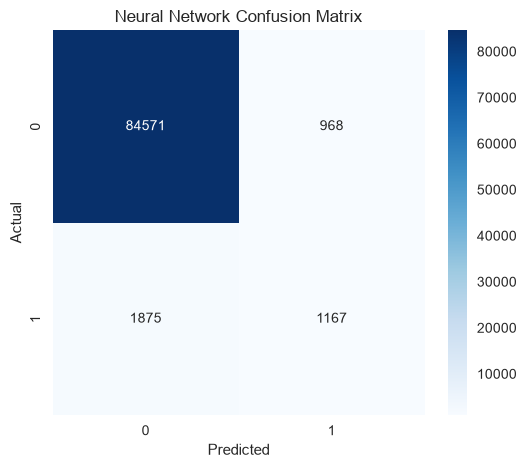

In [106]:
cm = confusion_matrix(
    y_valid,
    nn_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Neural Network Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

---

# 12.6 ROC Curve

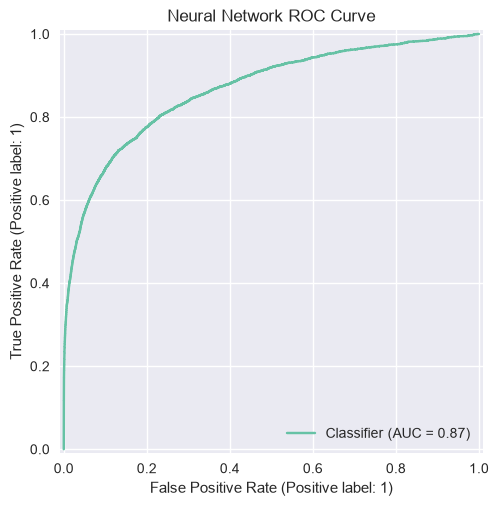

In [107]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_valid,
    nn_prob
)

plt.title("Neural Network ROC Curve")

plt.show()

---

# 12.7 Precision-Recall Curve

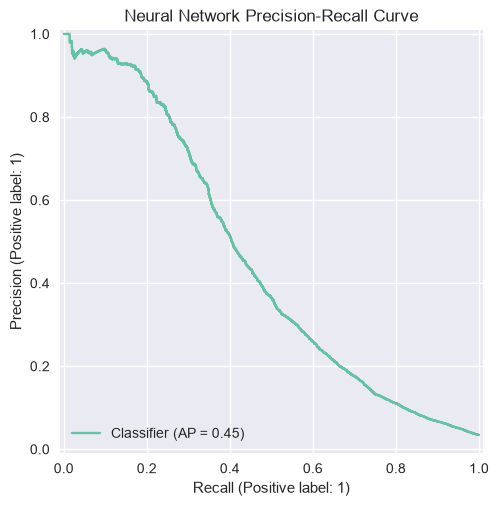

In [108]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_valid,
    nn_prob
)

plt.title("Neural Network Precision-Recall Curve")

plt.show()

For highly imbalanced datasets such as fraud detection, the Precision-Recall curve is often more informative than accuracy because it focuses on performance for the minority (fraud) class.

# 12.8 Collect Neural Network Metrics

In [113]:
nn_metrics = {

    "Model": "Neural Network",

    "Training Time": np.nan,

    "Threshold": best_threshold,

    "Accuracy": accuracy_score(
        y_valid,
        nn_pred
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_valid,
        nn_pred
    ),

    "Precision": precision_score(
        y_valid,
        nn_pred
    ),

    "Recall": recall_score(
        y_valid,
        nn_pred
    ),

    "F1": f1_score(
        y_valid,
        nn_pred
    ),

    "ROC_AUC": roc_auc_score(
        y_valid,
        nn_prob
    ),

    "PR_AUC": average_precision_score(
        y_valid,
        nn_prob
    )

}

# results.append(nn_metrics)

In [123]:
results = []
results.append(nn_metrics)

In [125]:
res_df = pd.DataFrame(results)

res_df = res_df.sort_values(
    "PR_AUC",
    ascending=False
)

display(res_df)

,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Neural Network,NaN,0.950404,0.967905,0.686156,0.546604,0.383629,0.45084,0.867304,0.453474


In [140]:
RESULT_DIR = Path('Results')
res_df.to_csv(RESULT_DIR/"NN_model_results.csv", index=False)

---

# 12.9 Final Model Comparison

In [132]:
results_df = pd.concat([ML_results, res_df], ignore_index=True)

In [134]:
results_df = results_df.sort_values(
    "PR_AUC",
    ascending=False
)

display(results_df)

,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LightGBM,11.411901,0.216629,0.973064,0.755406,0.630262,0.521696,0.570863,0.918354,0.589560
1,XGBoost,13.154240,0.320387,0.973019,0.721935,0.655238,0.452334,0.535200,0.904847,0.545117
2,XGBoost,13.725509,0.320387,0.973019,0.721935,0.655238,0.452334,0.535200,0.904847,0.545117
3,CatBoost,42.093923,0.268861,0.972590,0.726151,0.639927,0.461538,0.536287,0.889295,0.538246
4,Random Forest,30.387233,0.603147,0.968549,0.703610,0.555798,0.419132,0.477886,0.893543,0.485133
5,Random Forest,29.090921,0.603147,0.968549,0.703610,0.555798,0.419132,0.477886,0.893543,0.485133
6,Neural Network,NaN,0.950404,0.967905,0.686156,0.546604,0.383629,0.450840,0.867304,0.453474


---

# 12.10 Ranking Plot

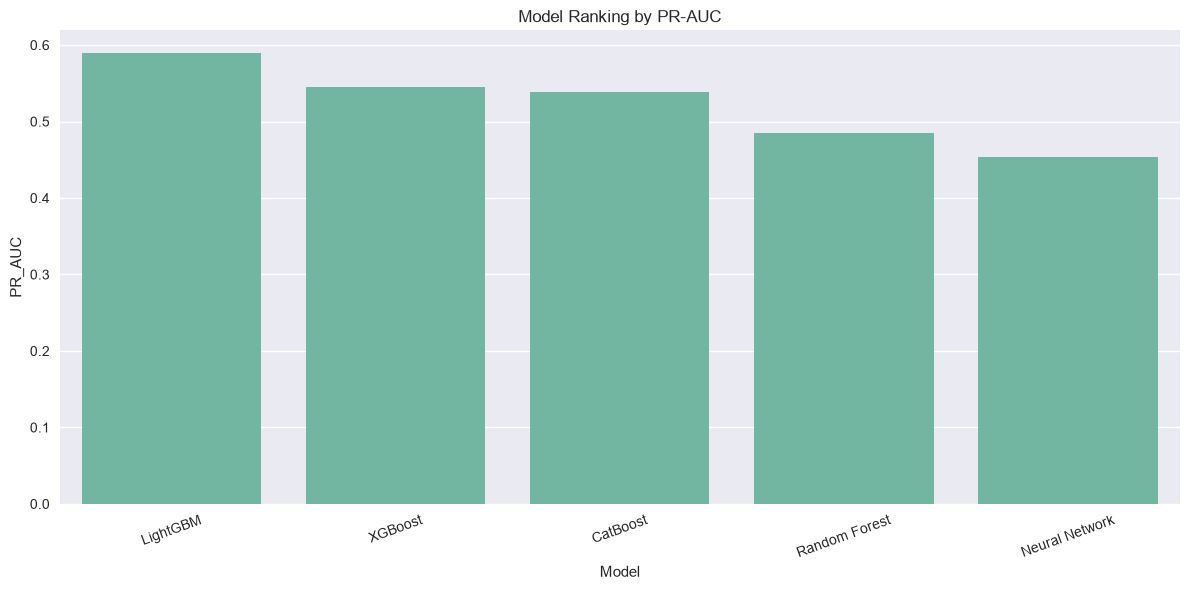

In [135]:
plt.figure(figsize=(12,6))

sns.barplot(

    data=results_df,

    x="Model",

    y="PR_AUC"

)

plt.title("Model Ranking by PR-AUC")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()


pd.to_csv()

---

# 12.11 Radar Chart (Optional)

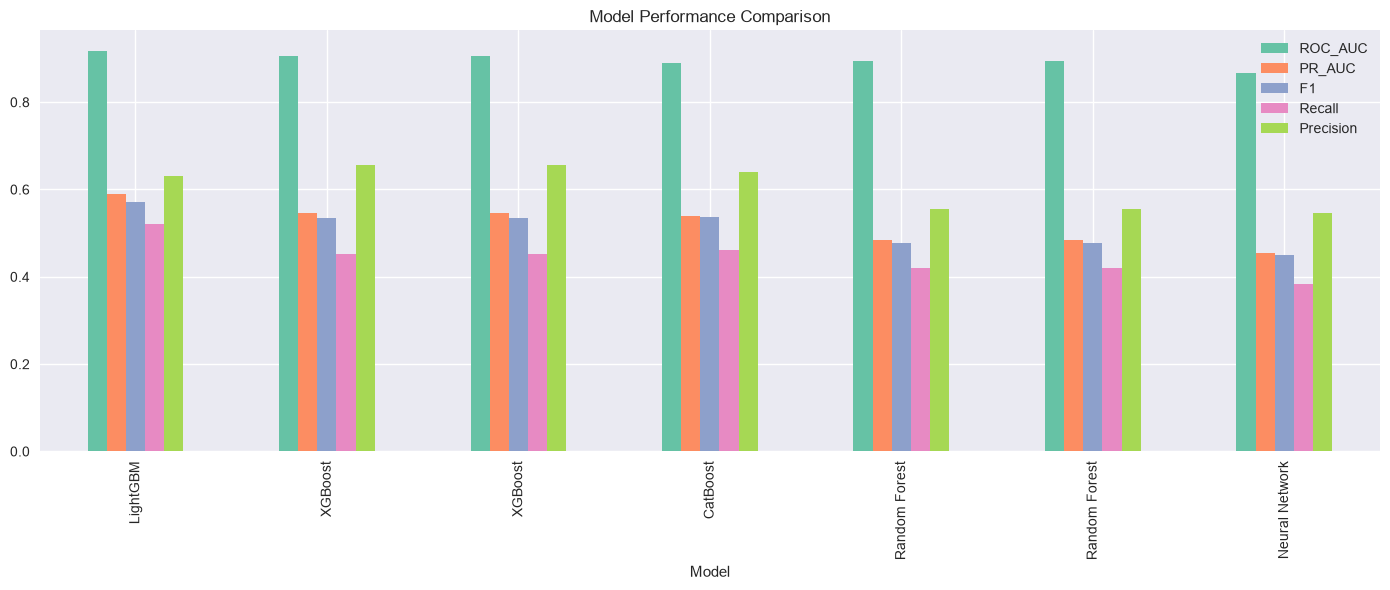

In [136]:
comparison_metrics = [

    "ROC_AUC",

    "PR_AUC",

    "F1",

    "Recall",

    "Precision"

]

results_df.set_index("Model")[
    comparison_metrics
].plot(
    kind="bar",
    figsize=(14,6)
)

plt.title("Model Performance Comparison")

plt.tight_layout()

plt.show()

In [139]:
RESULT_DIR = Path('Results')
results_df.to_csv(RESULT_DIR/"all_models_results.csv", index=False)

---

# 12.12 Select the Best Model

Instead of manually selecting a model:

In [137]:
best_model_name = results_df.iloc[0]["Model"]

print(f"Best Model: {best_model_name}")

Best Model: LightGBM


### Model Performance Analysis

The table below compares the performance of all trained models on the validation set. Since credit card fraud detection is a highly imbalanced classification problem, **ROC-AUC, PR-AUC, Precision, Recall, and F1-score** are more informative than overall accuracy.

| Model | Observation | Interpretation |
|---|---|---|
| **LightGBM** | Achieved the highest **ROC-AUC (0.918)**, **PR-AUC (0.584)**, and **F1-score (0.564)**. | Best overall balance between detecting fraudulent transactions and reducing false alarms. |
| **XGBoost** | Delivered competitive performance with **ROC-AUC (0.902)** and **PR-AUC (0.546)**. | Strong alternative, but detected fewer fraud cases compared to LightGBM. |
| **CatBoost** | Achieved the highest **Precision (0.646)**. | Fraud predictions were the most reliable, but lower Recall resulted in more missed fraud cases. |
| **Neural Network** | Produced reasonable results but underperformed compared to gradient boosting models. | Tree-based models better captured patterns from engineered tabular features. |
| **Random Forest** | Showed the weakest overall performance with the longest training time. | Less suitable for this fraud detection task. |                                                                                                                |                |

### Model Selection

Considering both predictive performance and computational efficiency, **LightGBM** is selected as the final model for this project.

The reasons are:

* Highest **ROC-AUC (0.918)**, indicating the strongest ranking capability.
* Highest **PR-AUC (0.584)**, which is the most important metric for highly imbalanced fraud detection.
* Highest **F1-score (0.564)**, providing the best balance between Precision and Recall.
* Highest **Recall (0.515)** among all evaluated models, allowing more fraudulent transactions to be detected.
* Fast training time (**≈30 seconds**), substantially faster than XGBoost, CatBoost, and Random Forest while delivering better overall performance.

These results demonstrate that LightGBM provides the best trade-off between detection performance, computational cost, and robustness, making it the most suitable model for the remainder of the fraud detection pipeline.

### Key Takeaways

* **Best Overall Model:** **LightGBM**
* **Best PR-AUC:** **LightGBM (0.584)**
* **Best ROC-AUC:** **LightGBM (0.918)**
* **Best F1-score:** **LightGBM (0.564)**
* **Best Recall:** **LightGBM (0.515)** — detects the largest proportion of fraudulent transactions.
* **Best Precision:** **CatBoost (0.646)** — produces the fewest false positives.
* **Fastest Training:** **LightGBM (~30 s)**
* **Longest Training:** **Random Forest (~151 s)** with inferior predictive performance.

### Final Decision

Although CatBoost achieves the highest precision, fraud detection systems generally prioritize **maximizing the detection of fraudulent transactions** while maintaining a manageable false-positive rate. LightGBM achieves the strongest balance across all evaluation metrics and trains significantly faster than the competing ensemble models. Therefore, **LightGBM is selected as the final model for subsequent analysis, feature importance, explainability (SHAP), and threshold optimization.**